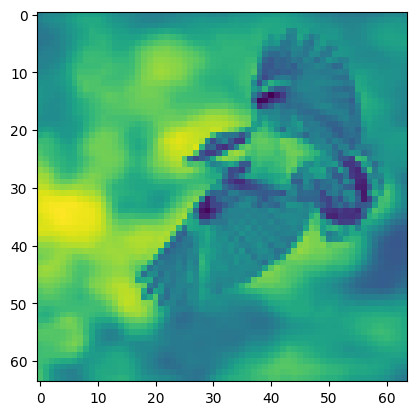

In [68]:

from matplotlib import pyplot as plt
from PIL import Image
import matplotlib.image as img
import numpy as np


sizexy=64
image = img.imread("dataset/NotRobin/NotRobin1.jpg")
Greyscale1=image.reshape(image.shape)[:, :, 0]
Greyscale = np.array(Image.fromarray(Greyscale1).resize((sizexy, sizexy)))
plt.imshow(Greyscale,interpolation='nearest')


[ 1  1  1  0  0  0 -1 -1 -1]
[[ 1  1  1]
 [ 0  0  0]
 [-1 -1 -1]]
[[ 10.   8.   3. ... -53. -50. -49.]
 [ 36.  37.  30. ... -37. -32. -28.]
 [ 26.  29.  25. ... -22. -21. -21.]
 ...
 [ 47.  81. 111. ...   9.  29.  44.]
 [ 34.  68.  94. ...  19.  33.  45.]
 [  1.  17.  26. ...  40.  44.  49.]]


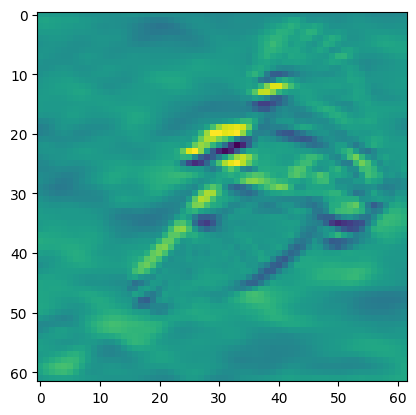

In [71]:

n=3
ans_xy=(sizexy-n+1)
#Convo_arr=[1,0,-1,1,0,-1,1,0,-1]#verticle

Convo_arr=[1,1,1,0,0,0,-1,-1,-1]#horizontal
#Convo_arr=[-1,1,-1,1,0,1,-1,1,-1]#horizontal


Convo_arr  = np.array(Convo_arr)
print(Convo_arr)
Convo_arr_new=Convo_arr.reshape((n, n))
print(Convo_arr_new)

ans=np.zeros((ans_xy,ans_xy))
i=0
j=0
Total=0
c=0
for k in range(ans_xy):
    for c in range(ans_xy):
        Total=0
        for i in range(n):
            for j in range(n) :
                temp=Greyscale[k+i][c+j]*Convo_arr_new[i][j]
                Total+=temp
                #print (temp)
        ans[k][c]=Total

plt.imshow(ans,interpolation='nearest')

print (ans)



[[ 10.   8.   3. ... -53. -50. -49.]
 [ 36.  37.  30. ... -37. -32. -28.]
 [ 26.  29.  25. ... -22. -21. -21.]
 ...
 [ 47.  81. 111. ...   9.  29.  44.]
 [ 34.  68.  94. ...  19.  33.  45.]
 [  1.  17.  26. ...  40.  44.  49.]]


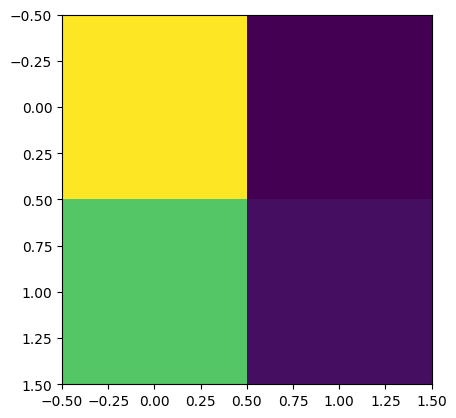

In [73]:
print(ans)
pool = 2#int(ans_xy/2)

pooled=np.zeros((pool,pool))
#filter 2*2
#2,2
i=0
j=0
c=0
k=0
for i in range(pool):
    for j in range(pool):
        biggest = 0
        
        row_start = i * pool
        row_end = row_start + pool
        col_start = j * pool
        col_end = col_start + pool
        
        for c in range(row_start, row_end):
            for k in range(col_start, col_end):
                #if ans[c][k] > biggest:
                biggest += ans[c][k]
                    
        pooled[i][j] = biggest/k



plt.imshow(pooled,interpolation='nearest')
